# Colorado Cannabis Legalization: Synthetic Control Analysis


## 1. Imports and paths

This section loads the libraries, defines the data locations, and sets the treatment unit and timing. Colorado is treated as the policy state beginning in 2014; the other selected states form the donor pool, and 2005–2013 is the pre-treatment period.


In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

DATA_DIR = Path(r"D:\Colorado_Project")
FARS_DIR = DATA_DIR / "FARS_Data"

MY_STATES = [
    "Colorado", "Idaho", "Montana", "Texas", "North Dakota", "South Dakota",
    "Iowa", "Missouri", "Arkansas", "Louisiana", "Mississippi", "Alabama",
    "Georgia", "South Carolina", "North Carolina", "Tennessee", "Kentucky",
    "Indiana", "Ohio", "Wisconsin", "Pennsylvania"
]
TREATMENT_UNIT = "Colorado"
TREATMENT_YEAR = 2014
PRE_YEARS = range(2005, 2014)


## 2. Data engineering

The source files are reshaped into a state-year panel and merged across traffic fatalities, GDP, unemployment, and population. Fatalities are converted to a rate per 100,000 residents, while GDP per capita is calculated for use as a comparable economic predictor. The resulting panel contains 315 observations and 10 variables.


In [2]:
def find_file(pattern: str) -> Path:
    matches = list(DATA_DIR.rglob(pattern))
    if not matches:
        raise FileNotFoundError(f"Could not find {pattern!r} below {DATA_DIR}")
    return matches[0]


def year_columns(frame: pd.DataFrame) -> list[str]:
    return [column for column in frame.columns if re.search(r"\d{4}", str(column))]


def reshape_fred(path: Path, value_name: str) -> pd.DataFrame:
    frame = pd.read_csv(path)
    state_column = "Region Name"
    columns = [state_column, *year_columns(frame)]
    long = frame.loc[:, columns].melt(
        id_vars=state_column, var_name="raw_date", value_name=value_name
    )
    long = long.rename(columns={state_column: "state"})
    long["year"] = long["raw_date"].astype(str).str.extract(r"(\d{4})")[0].astype(int)
    long[value_name] = pd.to_numeric(long[value_name], errors="coerce")
    return long.loc[long["state"].isin(MY_STATES), ["state", "year", value_name]]


def load_fars() -> pd.DataFrame:
    frames = []
    for path in FARS_DIR.rglob("*.csv"):
        frame = pd.read_csv(path)
        if "State" not in frame.columns:
            continue
        columns = year_columns(frame)
        if not columns:
            continue
        long = frame.loc[:, ["State", *columns]].melt(
            id_vars="State", var_name="year", value_name="total_fatalities"
        )
        long = long.rename(columns={"State": "state"})
        long["year"] = pd.to_numeric(long["year"], errors="coerce")
        long["total_fatalities"] = pd.to_numeric(long["total_fatalities"], errors="coerce")
        frames.append(long)
    if not frames:
        raise FileNotFoundError("No FARS CSV containing State and four-digit year columns was found.")
    fars = pd.concat(frames, ignore_index=True)
    fars = fars.loc[fars["state"].isin(MY_STATES)].drop_duplicates(["state", "year"])
    return fars


fars_clean = load_fars()
gdp_clean = reshape_fred(
    find_file("*Real Gross Domestic Product*.csv"), "real_gdp"
)
unemp_clean = reshape_fred(
    find_file("*Unemployment Rate*.csv"), "unemp_rate"
)
pop_clean = reshape_fred(
    find_file("*Resident Population*.csv"), "pop_thousands"
)

final_panel = (
    fars_clean.merge(gdp_clean, on=["state", "year"], how="inner")
    .merge(unemp_clean, on=["state", "year"], how="inner")
    .merge(pop_clean, on=["state", "year"], how="inner")
)
final_panel["actual_pop"] = final_panel["pop_thousands"] * 1_000
final_panel["fatalities_per_100k"] = (
    final_panel["total_fatalities"] / final_panel["actual_pop"] * 100_000
)
final_panel["gdp_per_capita"] = (
    final_panel["real_gdp"] * 1_000_000 / final_panel["actual_pop"]
)
state_ids = pd.DataFrame({"state": MY_STATES, "state_id": range(1, len(MY_STATES) + 1)})
final_panel = (
    final_panel.merge(state_ids, on="state", how="inner")
    .sort_values(["state", "year"])
    .reset_index(drop=True)
)

print(final_panel.shape)
display(final_panel.head())


(315, 10)


,state,year,total_fatalities,real_gdp,unemp_rate,pop_thousands,actual_pop,fatalities_per_100k,gdp_per_capita,state_id
0,Alabama,2005,"1,148.000","197,246.475",4.458,"4,569.805","4,569,805.000",25.121,"43,162.996",12
1,Alabama,2006,"1,207.000","199,923.875",4.008,"4,628.981","4,628,981.000",26.075,"43,189.608",12
2,Alabama,2007,"1,110.000","202,025.475",4.067,"4,672.840","4,672,840.000",23.754,"43,233.981",12
3,Alabama,2008,969.000,"200,967.450",5.917,"4,718.206","4,718,206.000",20.537,"42,594.039",12
4,Alabama,2009,848.000,"194,192.050",9.733,"4,757.938","4,757,938.000",17.823,"40,814.330",12


## 3. Synthetic-control estimator

The estimator constructs a synthetic Colorado as a weighted average of donor states. Weights are nonnegative and sum to one, and are chosen to match Colorado's pre-treatment predictors and outcome history as closely as possible. The difference between Colorado and its synthetic counterpart is interpreted as the estimated treatment gap.


In [3]:
def fit_weights(target: np.ndarray, donors: np.ndarray) -> np.ndarray:
    """Estimate nonnegative donor weights with a numerically stable objective."""
    n_donors = donors.shape[1]
    scale = np.nanstd(donors, axis=1)
    scale[~np.isfinite(scale) | (scale < 1e-12)] = 1.0
    target_scaled = np.nan_to_num(target / scale)
    donors_scaled = np.nan_to_num(donors / scale[:, None])
    initial = np.full(n_donors, 1 / n_donors)
    result = minimize(
        lambda weights: float(np.sum((target_scaled - donors_scaled @ weights) ** 2)),
        initial,
        method="SLSQP",
        bounds=[(0.0, 1.0)] * n_donors,
        constraints={"type": "eq", "fun": lambda weights: np.sum(weights) - 1},
        options={"ftol": 1e-10, "maxiter": 10_000},
    )
    if not result.success:
        raise RuntimeError(f"Synthetic-control optimization failed: {result.message}")
    return result.x


def make_predictors(data: pd.DataFrame, outcome: str, predictor_spec: dict) -> pd.DataFrame:
    rows = {}
    for name, (column, years) in predictor_spec.items():
        values = data.loc[data["year"].isin(years)].groupby("state")[column].mean()
        rows[name] = values
    predictors = pd.DataFrame(rows)
    outcome_values = data.loc[data["year"].isin(PRE_YEARS)].pivot(
        index="state", columns="year", values=outcome
    )
    return predictors.join(outcome_values.add_prefix("outcome_"), how="inner")


def synthetic_control(data: pd.DataFrame, outcome: str, predictor_spec: dict) -> dict:
    units = [unit for unit in MY_STATES if unit in set(data["state"])]
    donors = [unit for unit in units if unit != TREATMENT_UNIT]
    predictors = make_predictors(data, outcome, predictor_spec).loc[units]
    predictor_columns = list(predictor_spec)
    target = predictors.loc[TREATMENT_UNIT, predictor_columns].to_numpy(float)
    donor_matrix = predictors.loc[donors, predictor_columns].to_numpy(float).T
    weights = fit_weights(np.nan_to_num(target), np.nan_to_num(donor_matrix))
    donor_weights = pd.Series(weights, index=donors, name="weight")

    outcome_panel = data.pivot(index="year", columns="state", values=outcome)
    synthetic = outcome_panel[donors].mul(weights, axis=1).sum(axis=1)
    actual = outcome_panel[TREATMENT_UNIT]
    gaps = actual - synthetic
    pre_mask = outcome_panel.index < TREATMENT_YEAR
    post_mask = outcome_panel.index >= TREATMENT_YEAR
    pre_mspe = float(np.mean(gaps.loc[pre_mask] ** 2))
    post_mspe = float(np.mean(gaps.loc[post_mask] ** 2))

    placebo_gaps = {}
    for unit in units:
        placebo_donors = [candidate for candidate in units if candidate != unit]
        placebo_target = predictors.loc[unit, predictor_columns].to_numpy(float)
        placebo_donor_matrix = predictors.loc[placebo_donors, predictor_columns].to_numpy(float).T
        placebo_weights = fit_weights(
            np.nan_to_num(placebo_target),
            np.nan_to_num(placebo_donor_matrix),
        )
        placebo_series = outcome_panel[placebo_donors].mul(placebo_weights, axis=1).sum(axis=1)
        placebo_gaps[unit] = outcome_panel[unit] - placebo_series
    placebo_gaps = pd.DataFrame(placebo_gaps)
    placebo_pre_mspe = (placebo_gaps.loc[pre_mask] ** 2).mean()
    placebo_post_mspe = (placebo_gaps.loc[post_mask] ** 2).mean()
    ratios = placebo_post_mspe / placebo_pre_mspe.replace(0, np.nan)
    treated_ratio = float(ratios[TREATMENT_UNIT])
    rank = int(ratios.rank(method="min", ascending=False)[TREATMENT_UNIT])
    p_value = float((ratios >= treated_ratio).sum() / ratios.notna().sum())

    balance = []
    for name in predictor_columns:
        donor_average = float(np.dot(donor_weights, predictors.loc[donors, name]))
        balance.append({
            "variable": name,
            "Colorado": float(predictors.loc[TREATMENT_UNIT, name]),
            "synthetic_Colorado": donor_average,
            "donor_sample": float(predictors.loc[donors, name].mean()),
        })

    return {
        "outcome": outcome,
        "weights": donor_weights,
        "actual": actual,
        "synthetic": synthetic,
        "gaps": gaps,
        "placebo_gaps": placebo_gaps,
        "balance": pd.DataFrame(balance),
        "significance": pd.DataFrame([{
            "pre_mspe": pre_mspe,
            "post_mspe": post_mspe,
            "mspe_ratio": treated_ratio,
            "rank": rank,
            "fishers_exact_pvalue": p_value,
        }]),
    }

## 4. Estimate the three models

Three separate models estimate the policy's association with real GDP, unemployment, and traffic fatalities. Each model uses outcome-specific historical averages together with the other pre-treatment characteristics, allowing the quality and size of the estimated gap to be assessed separately for each outcome.


In [4]:
all_pre = range(2005, 2014)
synth_fars = synthetic_control(final_panel, "fatalities_per_100k", {
    "unemp_rate": ("unemp_rate", all_pre),
    "gdp_per_capita": ("gdp_per_capita", all_pre),
    "fatalities_early": ("fatalities_per_100k", range(2005, 2008)),
    "fatalities_recession": ("fatalities_per_100k", range(2008, 2011)),
    "fatalities_pre": ("fatalities_per_100k", range(2011, 2014)),
})
synth_gdp = synthetic_control(final_panel, "real_gdp", {
    "unemp_rate": ("unemp_rate", all_pre),
    "fatalities_per_100k": ("fatalities_per_100k", all_pre),
    "gdp_early": ("real_gdp", range(2005, 2008)),
    "gdp_recession": ("real_gdp", range(2008, 2011)),
    "gdp_pre": ("real_gdp", range(2011, 2014)),
})
synth_unemp = synthetic_control(final_panel, "unemp_rate", {
    "gdp_per_capita": ("gdp_per_capita", all_pre),
    "fatalities_per_100k": ("fatalities_per_100k", all_pre),
    "unemp_early": ("unemp_rate", range(2005, 2008)),
    "unemp_recession": ("unemp_rate", range(2008, 2011)),
    "unemp_pre": ("unemp_rate", range(2011, 2014)),
})

models = {
    "Panel A: Real GDP Model": synth_gdp,
    "Panel B: Unemployment Model": synth_unemp,
    "Panel C: Traffic Fatalities Model": synth_fars,
}
print("Models estimated successfully.")

Models estimated successfully.


## 5. Predictor balance tables

These tables compare Colorado with its synthetic counterpart and with the unweighted donor average. The synthetic values are generally closer to Colorado than the donor average, indicating that the weighting procedure improves pre-treatment comparability. Remaining differences show where the synthetic control is an imperfect match.


In [5]:
for label, model in models.items():
    print(f"\n=== {label.upper()} PREDICTOR BALANCE ===")
    display(model["balance"].round(2))

combined_balance = pd.concat(
    [model["balance"].assign(Model=label) for label, model in models.items()],
    ignore_index=True,
)[["Model", "variable", "Colorado", "synthetic_Colorado", "donor_sample"]]
combined_balance = combined_balance.rename(columns={
    "variable": "Variable",
    "synthetic_Colorado": "Synthetic Colorado",
    "donor_sample": "Donor Average",
})
display(combined_balance.round(2))


=== PANEL A: REAL GDP MODEL PREDICTOR BALANCE ===


,variable,Colorado,synthetic_Colorado,donor_sample
0,unemp_rate,6.480,6.410,6.550
1,fatalities_per_100k,10.270,11.340,16.680
2,gdp_early,"269,639.180","290,194.360","296,677.480"
3,gdp_recession,"278,949.320","287,337.050","302,095.340"
4,gdp_pre,"291,595.820","301,834.340","318,248.610"



=== PANEL B: UNEMPLOYMENT MODEL PREDICTOR BALANCE ===


,variable,Colorado,synthetic_Colorado,donor_sample
0,gdp_per_capita,"56,463.750","52,375.000","48,102.960"
1,fatalities_per_100k,10.270,11.240,16.680
2,unemp_early,4.340,4.730,4.780
3,unemp_recession,7.310,7.120,7.550
4,unemp_pre,7.800,7.380,7.320



=== PANEL C: TRAFFIC FATALITIES MODEL PREDICTOR BALANCE ===


,variable,Colorado,synthetic_Colorado,donor_sample
0,unemp_rate,6.480,6.460,6.550
1,gdp_per_capita,"56,463.750","52,261.970","48,102.960"
2,fatalities_early,11.980,12.350,19.570
3,fatalities_recession,9.820,10.660,15.790
4,fatalities_pre,9.000,9.940,14.690


,Model,Variable,Colorado,Synthetic Colorado,Donor Average
0,Panel A: Real GDP Model,unemp_rate,6.480,6.410,6.550
1,Panel A: Real GDP Model,fatalities_per_100k,10.270,11.340,16.680
2,Panel A: Real GDP Model,gdp_early,"269,639.180","290,194.360","296,677.480"
3,Panel A: Real GDP Model,gdp_recession,"278,949.320","287,337.050","302,095.340"
4,Panel A: Real GDP Model,gdp_pre,"291,595.820","301,834.340","318,248.610"
5,Panel B: Unemployment Model,gdp_per_capita,"56,463.750","52,375.000","48,102.960"
6,Panel B: Unemployment Model,fatalities_per_100k,10.270,11.240,16.680
7,Panel B: Unemployment Model,unemp_early,4.340,4.730,4.780
8,Panel B: Unemployment Model,unemp_recession,7.310,7.120,7.550
9,Panel B: Unemployment Model,unemp_pre,7.800,7.380,7.320


## 6. Statistical significance table

MSPE measures the average squared gap before and after treatment; a larger post/pre MSPE ratio indicates a larger deterioration in fit after 2014. The placebo rank and p-value compare Colorado's ratio with those obtained when each donor state is treated as if it were exposed. 

In [6]:
combined_sig = pd.concat([
    synth_gdp["significance"].assign(Outcome="Real GDP"),
    synth_unemp["significance"].assign(Outcome="Unemployment Rate"),
    synth_fars["significance"].assign(Outcome="Traffic Fatalities"),
], ignore_index=True)[[
    "Outcome", "pre_mspe", "post_mspe", "mspe_ratio", "rank", "fishers_exact_pvalue"
]].rename(columns={
    "pre_mspe": "Pre-MSPE",
    "post_mspe": "Post-MSPE",
    "mspe_ratio": "MSPE Ratio",
    "rank": "Rank",
    "fishers_exact_pvalue": "P-Value",
})
display(combined_sig.round(3))

,Outcome,Pre-MSPE,Post-MSPE,MSPE Ratio,Rank,P-Value
0,Real GDP,"213,663,183.254","676,680,265.816",3.167,13,0.619
1,Unemployment Rate,0.419,2.957,7.059,3,0.143
2,Traffic Fatalities,0.761,2.989,3.925,2,0.095


## 7. Trend, gap, and placebo plots

The trend plots show Colorado and synthetic Colorado over time, with the vertical line marking legalization. The gap plots display the difference between the two series, while the placebo plots place Colorado's gap alongside gaps generated for the donor states. A post-2014 gap is suggestive only when it is large relative to the placebo distribution and follows a good pre-treatment fit.


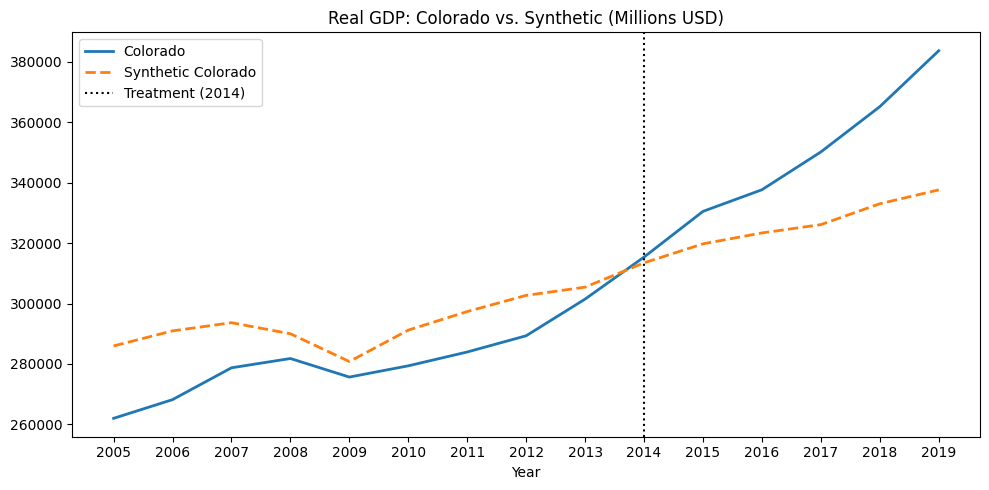

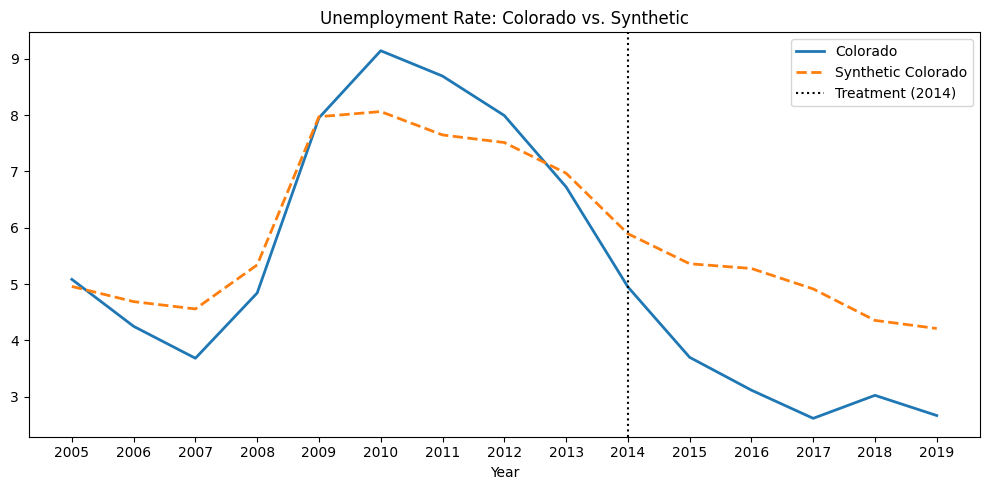

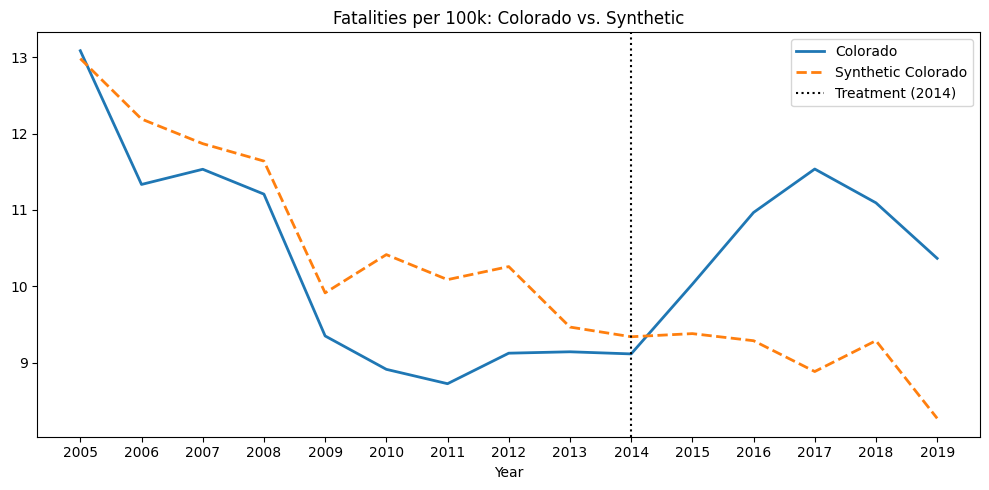

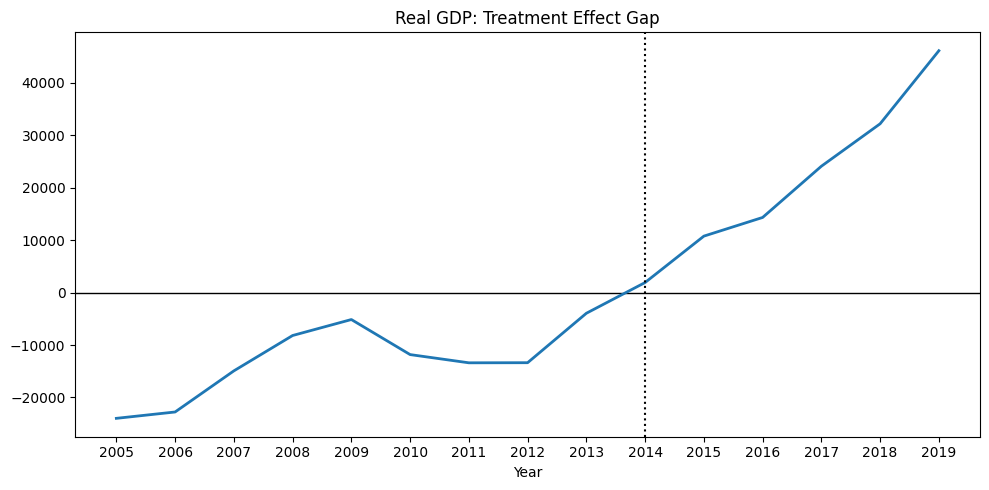

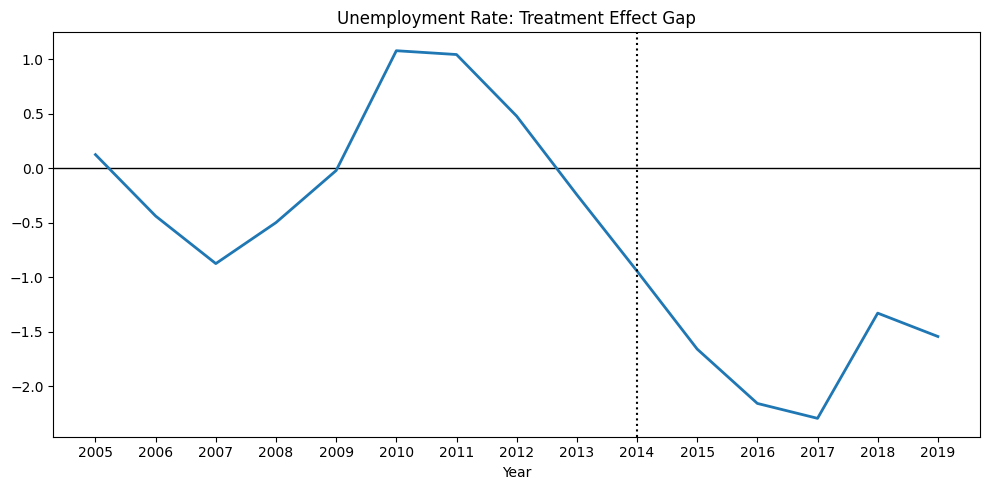

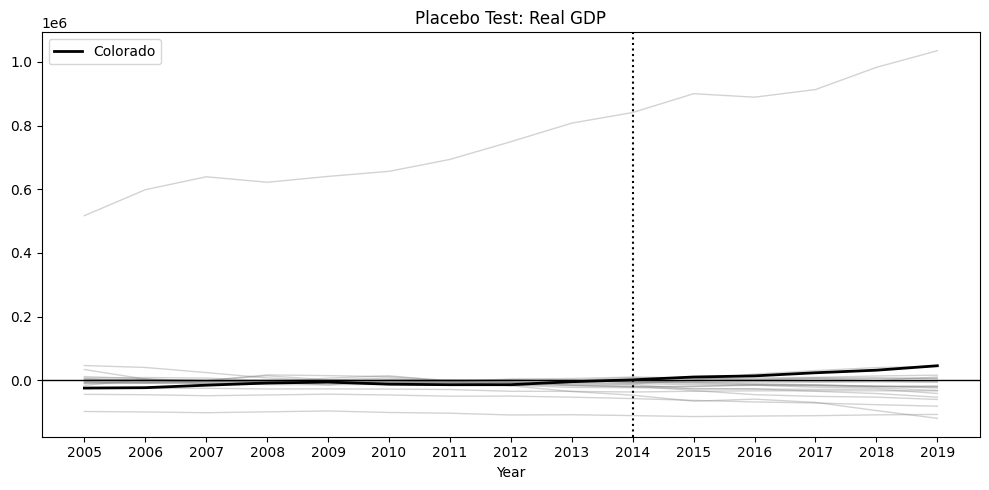

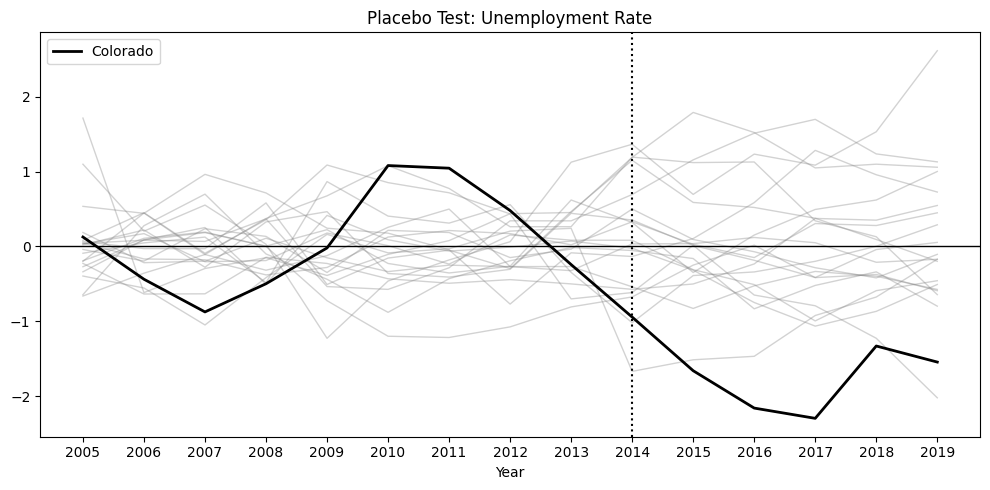

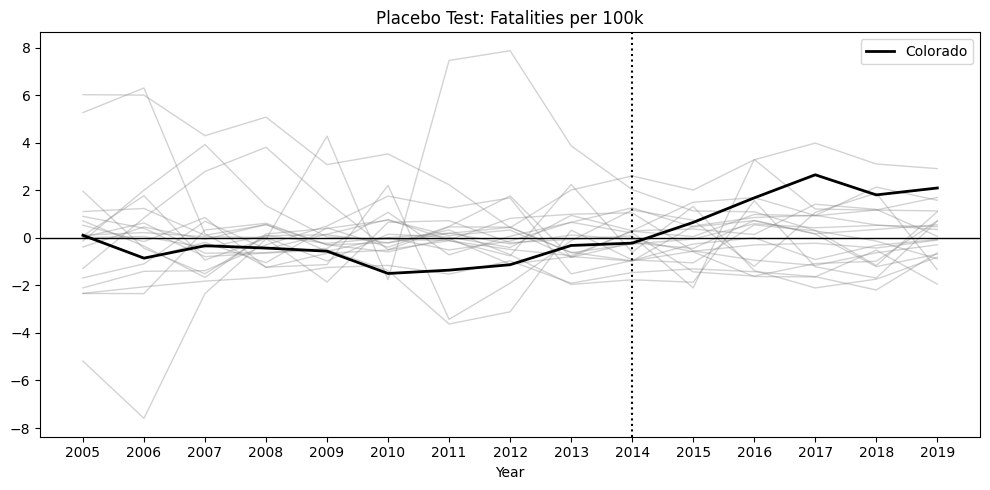

In [7]:
def plot_trends(model: dict, title: str) -> None:
    plt.figure(figsize=(10, 5))
    plt.plot(model["actual"].index, model["actual"], label="Colorado", linewidth=2)
    plt.plot(model["synthetic"].index, model["synthetic"], label="Synthetic Colorado", linewidth=2, linestyle="--")
    plt.axvline(TREATMENT_YEAR, color="black", linestyle=":", label="Treatment (2014)")
    plt.title(title)
    plt.xlabel("Year")
    plt.legend()
    plt.xticks(range(2005, 2020))
    plt.tight_layout()
    plt.show()


def plot_gap(model: dict, title: str) -> None:
    plt.figure(figsize=(10, 5))
    plt.axhline(0, color="black", linewidth=1)
    plt.plot(model["gaps"].index, model["gaps"], linewidth=2)
    plt.axvline(TREATMENT_YEAR, color="black", linestyle=":")
    plt.title(title)
    plt.xlabel("Year")
    plt.xticks(range(2005, 2020))
    plt.tight_layout()
    plt.show()


def plot_placebos(model: dict, title: str) -> None:
    plt.figure(figsize=(10, 5))
    for unit in model["placebo_gaps"].columns:
        line = model["placebo_gaps"][unit]
        plt.plot(line.index, line, color="gray", alpha=0.35, linewidth=1)
    plt.plot(model["gaps"].index, model["gaps"], color="black", linewidth=2, label="Colorado")
    plt.axhline(0, color="black", linewidth=1)
    plt.axvline(TREATMENT_YEAR, color="black", linestyle=":")
    plt.title(title)
    plt.xlabel("Year")
    plt.xticks(range(2005, 2020))
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_trends(synth_gdp, "Real GDP: Colorado vs. Synthetic (Millions USD)")
plot_trends(synth_unemp, "Unemployment Rate: Colorado vs. Synthetic")
plot_trends(synth_fars, "Fatalities per 100k: Colorado vs. Synthetic")
plot_gap(synth_gdp, "Real GDP: Treatment Effect Gap")
plot_gap(synth_unemp, "Unemployment Rate: Treatment Effect Gap")
plot_placebos(synth_gdp, "Placebo Test: Real GDP")
plot_placebos(synth_unemp, "Placebo Test: Unemployment Rate")
plot_placebos(synth_fars, "Placebo Test: Fatalities per 100k")